## EU REED

#### 1) Import packages, background databases and set project

In [ ]:
import bw2data as bd
import bw2calc as bc
import bw2io as bi
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import bw2analyzer as bwa
from reed.utils import Config
import bw_processing as bwp
from bw2io.strategies.generic import set_code_by_activity_hash


import matplotlib.pyplot as plt
import d3graph
import polyviz

from datetime import date

In [ ]:
bi.remote.install_project(project_key="ecoinvent-3.10-biosphere", overwrite_existing=False)

In [3]:
config = Config()

In [4]:
bd.projects.set_current(config.PROJECT_NAME)

In [5]:
import import_db

#### 2) Import foreground database 

In [8]:
from bw2io.importers import ExcelImporter
from reed.utils import Config

importer  = ExcelImporter(config.REED_PATH/'model'/'REED_model_20260407.xlsx',)
importer.apply_strategies()
importer.match_database(fields=['name','unit','location'])
importer.match_database(db_name=bonsai.name,fields=['name','unit','location','activity type'])
importer.match_database(db_name=bd.config.biosphere,fields=['name','categories','unit'])

Extracted 6 worksheets in 0.56 seconds
Applying strategy: csv_restore_tuples
Applying strategy: csv_restore_booleans
Applying strategy: csv_numerize
Applying strategy: csv_drop_unknown
Applying strategy: csv_add_missing_exchanges_section
Applying strategy: normalize_units
Applying strategy: normalize_biosphere_categories
Applying strategy: normalize_biosphere_names
Applying strategy: strip_biosphere_exc_locations
Applying strategy: set_code_by_activity_hash
Applying strategy: link_iterable_by_fields
Applying strategy: assign_only_product_as_production
Applying strategy: link_technosphere_by_activity_hash
Applying strategy: drop_falsey_uncertainty_fields_but_keep_zeros
Applying strategy: convert_uncertainty_types_to_integers
Applying strategy: convert_activity_parameters_to_list
Applied 16 strategies in 0.50 seconds
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields


In [9]:
importer.statistics()

Graph statistics for `reed` importer:
77 graph nodes:
	None: 77
423 graph edges:
	technosphere: 344
	production: 77
	biosphere: 2
423 edges to the following databases:
	BONSAI_V2.1.3: 240
	reed: 181
	ecoinvent-3.10-biosphere: 2
0 unique unlinked edges (0 total):




(77, 423, 0, 0)

In [10]:
importer.write_database()

100%|██████████| 77/77 [00:00<00:00, 854.86it/s]


09:45:44+0200 [info     ] Vacuuming database            
Created database: reed


In [11]:
pd.DataFrame(importer.unlinked)

""


In [13]:
data_reed = [activity.as_dict() for activity in reed]
df_reed = pd.DataFrame(data_reed)


In [14]:
from IPython.display import display
display(df_reed[['name', 'comment', 'location', 'unit', 'database']])

,name,comment,location,unit,database
0,Casting,Continious steel casting. Data from a polish f...,DE,ton,reed
1,GOIMEK A2: transport,None,ES,unit,reed
2,GOIMEK A1: material input,None,ES,unit,reed
3,"milling, soraluce",proxy for milling. Waiting for primary electri...,ES,hour,reed
4,"transport, lorry",None,ES,ton kilometer,reed
...,...,...,...,...,...
72,drilling,None,ES,hour,reed
73,"generic machining, soraluce",to be used as proxy when machining process is ...,GB,hour,reed
74,painting,None,DE,square meter,reed
75,chamfer,None,ES,hour,reed


In [ ]:
bonsai = bd.Database('BONSAI_V2.1.3')
bonsai_bio = bd.Database('BONSAI_V2.1.3 biosphere')
ecoinvent = bd.Database('ecoinvent-3.10-biosphere')
reed = bd.Database('reed')

In [15]:
bd.databases

Databases dictionary with 4 object(s):
	BONSAI_V2.1.3
	BONSAI_V2.1.3 biosphere
	ecoinvent-3.10-biosphere
	reed

#### 3) Importing sensordata
###### This part draws from defined functions in the script, sensordata_analysis.py. It imports the monitoring data and calculates the energy consumption per tool and connect the tools to the reed tools

In [ ]:
from reed.sensordata_analysis import (
    run_sensordata_analysis,
    find_missing_op_type_tools,
    compute_event_totals,
    split_final_df_by_company_event,
    sum_by_reed_tool,
    split_final_df_by_company_event,
)

In [ ]:
monitoring_data_path = config.REED_PATH/'Data'/"MonitoringData"/"Data"
tool_descriptions_path = config.REED_PATH/'Data'/"MonitoringData"

In [ ]:
sensordata, event_summaries_df, ambiguous_company_tools, key_company_tools, key_reed_tools = run_sensordata_analysis(
    monitoring_data_path,
    tool_descriptions_path,
)
print(sensordata)

Identify tools that have different operation type in the key_company_tools. These tool numbers are removed from the key to avoid an ambigious key. These tool numbers will be assigned to the generic machining process in the reed database

In [ ]:
print(ambiguous_company_tools)

In [ ]:
#Identify missing op type tools, e.g. tools that are in the monitoring data but not in tool descriptions
missing_tool_descriptions = find_missing_op_type_tools(sensordata)

In [ ]:
#Compute total time and energy per event per company
event_totals = compute_event_totals(sensordata, event_summaries_df)

#### 4) Switching in sensordata

this section is missing a part about how to handle the processes that are not in hours?

In [ ]:
from reed.swapping_data import (
    find_activities_by_name,
    build_scenarios_from_power_active,
    build_consumer_input_scenarios_from_hours,
    describe_scenarios,
    lcia_for_activity_with_scenario,
)

Select which event you want to analyse

In [ ]:
company = "komatsu"
event_id = "OF10006_G_SLG_E8AJ1C"
product = "Komatsu piece"
demand = 1

Start by selected the company and event_id where you want to swap in the sensordata

In [ ]:
#Split sensordata by company and event
event_dfs = split_final_df_by_company_event(sensordata)

#Compute energy by reed tool for a specific company and event
tool_energy_by_company_and_event = sum_by_reed_tool(
    event_dfs[(company, event_id)]
)
print(tool_energy_by_company_and_event)

Find all processes present in the sensordata in the reed-database

In [ ]:
tools = tool_energy_by_company_and_event.index.get_level_values("reed tool").unique()
found = {t: find_activities_by_name(reed, t, exact=False) for t in tools}
found

In [ ]:
#Identifying the electricity activity in bonsai to be able to compute the original electricity input amount for the activities found above
electricity = bonsai.get(name='production of electricity (market for)', location='GB', unit='TJ')

Create scenario where alle electricity inputs from the sensordata to the processes identified in found.

In [ ]:
scenarios = build_scenarios_from_power_active(tool_energy_by_company_and_event, found, electricity)


The input of products in found to consuming activities are found and used to build scenarios.

In [ ]:
consumer_scenarios = build_consumer_input_scenarios_from_hours(tool_energy_by_company_and_event, found, reed)

In [ ]:
full_scenario = pd.concat([scenarios, consumer_scenarios])

In [ ]:
full_scenario_readable = describe_scenarios(full_scenario)
full_scenario_readable

Calculate a LCA score for a specific activity and scenario

In [ ]:
score, lca = lcia_for_activity_with_scenario(
    activity=reed.get(name=product),
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    scenario_col=None,     # "original" or None (for defined scenario)
    amount=demand
)
score


Baseline LCA score for same product

In [ ]:
product_reed = reed.get(name=product)
lca = product_reed.lca(method=config.lcia_gwp100)
lca.score

#### 5) Align data to Digital Product Passport (DPP)

In [ ]:
activity = reed.get(name=product)
location = activity.get("location")
unit = activity.get("unit")

# Make sure results are defined as score_a1, score_a2, score_a3
score_A1 = score_a1
score_A2 = score_a2
score_A3 = score_a3

def make_pcf_entry(score, life_cycle_phase):
    return {
        "PcfCalculationMethods": [
            {
                "PcfCalculationMethod": "ISO 14044"
            }
        ],
        "PcfCO2eq": round(score, 1),
        "ReferenceValueForCalculation": unit,
        "QuantityOfMeasureForCalculation": demand,
        "LifeCyclePhases": [
            {
                "LifeCyclePhase": life_cycle_phase
            }
        ],
        "ExplanatoryStatement": (
            "Consequential approach modelling the climate impact of demanding "
            "the specific product."
        ),
        "GoodsHandoverAddress": {
            "Country": location
        },
        "PublicationDate": date.today().isoformat(),
        # "ExpirationDate": "2027-03-06"
    }

dpp_output = {
    "DPP": [
        {
            "company": company,
            "event_id": event_id,
            "product": product,
            "carbonFootprint": {
                "ProductCarbonFootprints": [
                    make_pcf_entry(score_A1, "A1"),
                    make_pcf_entry(score_A2, "A2"),
                    make_pcf_entry(score_A3, "A3"),
                    make_pcf_entry(score_A1 + score_A2 + score_A3, "A1-A3")  # optional total
                ]
            }
        }
    ]
}

dpp_output


#### 6) Defining LCIA functions

In [20]:
def lca_score(process_dict, method):
    results = []
    for name, process in process_dict.items():
        lca = process.lca(method)
        results.append({
            "Process": name,
            "Location": process.get('location'),
            "Functional Unit": process.get('unit'),
            "Climate Impact (kg CO2eq)": lca.score
        })

    return pd.DataFrame(results)

In [21]:
def run_contribution_analysis(demand_object,
                              lcia_method,
                              max_level=1,
                              cutoff=0.01):
    return bwa.utils.recursive_calculation_to_object(
        demand_object,
        lcia_method=lcia_method,
        max_level=max_level,
        cutoff=cutoff,
        as_dataframe=True,
    )

In [ ]:
def plot_contribution(df,
                      title='Contribution Analysis',
                      xlabel='CO2 eq. emissions (kg)',
                      drop_parent=True):
    df_plot = df.copy()

    # Drop the parent (the demand itself)
    if drop_parent:
        # Heuristic: parent is usually the one with maximum score
        parent_score = df_plot['score'].max()
        df_plot = df_plot[df_plot['score'] < parent_score]

    # Sort descending by contribution
    df_plot = df_plot.sort_values(by='score', ascending=False)

    f, ax = plt.subplots(figsize=(5, 2))
    sns.barplot(y='name', x='score', data=df_plot, ax=ax)

    ax.set(
        title=title,
        xlabel=xlabel,
        ylabel=''
    )
    plt.tight_layout()
    plt.show()

#### 7) Define processes for PCF calculation

In [26]:
reed.search('goimek')

['GOIMEK A2: transport' (unit, ES, None),
 'GOIMEK A3: machining' (unit, ES, None),
 'Soraluce machining, GOIMEK' (unit, ES, None),
 'soraluce machine, Goimek' (unit, ES, None),
 'GOIMEK A1: material input' (unit, ES, None),
 'GOIMEK total' (unit, ES, None)]

In [ ]:
komatsu_processes = {
    "KOMATSU total": reed.get(name='KOMATSU total', location="GB", unit='unit'),
    "KOMATSU A1: raw materials": reed.get(name='KOMATSU A1: raw materials', location="GB", unit='unit'),
    "KOMATSU A2: transport": reed.get(name='KOMATSU A2: transport', location="GB", unit='unit'),
    "KOMATSU A3: machining": reed.get(name='KOMATSU A3: machining', location="GB", unit='unit'),
    
}

In [ ]:
wwr_processes = {
    "WWR total": reed.get(name='WWR total', location="DE", unit='unit'),
    "WWR A1: material inputs": reed.get(name='WWR A1: material inputs', location="DE", unit='unit'),
    "WWR A2: transport": reed.get(name='WWR A2: transport', location="DE", unit='unit'),
    "WWR A3: machining": reed.get(name='WWR A3: machining', location="DE", unit='unit'),
}

In [27]:
goimek_processes = {
    "GOIMEK total": reed.get(name='GOIMEK total', location="ES", unit='unit'),
    "GOIMEK A1: material input": reed.get(name='GOIMEK A1: material input', location="ES", unit='unit'),
    "GOIMEK A2: transport": reed.get(name='GOIMEK A2: transport', location="ES", unit='unit'),
    "GOIMEK A3: machining": reed.get(name='GOIMEK A3: machining', location="ES", unit='unit'),
}

#### 8) PCF results in A1, A2 and A3

In [34]:
df_komatsu_results = lca_score(komatsu_processes, config.lcia_gwp100)
display(df_komatsu_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,KOMATSU total,GB,unit,11237.992927
1,KOMATSU A1: raw materials,GB,unit,10489.841046
2,KOMATSU A2: transport,GB,unit,110.146444
3,KOMATSU A3: machining,GB,unit,923.069887


In [35]:
df_wwr_results = lca_score(wwr_processes, config.lcia_gwp100)
display(df_wwr_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,WWR total,DE,unit,40534.427092
1,WWR A1: material inputs,DE,unit,40124.436988
2,WWR A2: transport,DE,unit,418.576158
3,WWR A3: machining,DE,unit,1069.550670


In [36]:
df_goimek_results = lca_score(goimek_processes, config.lcia_gwp100)
display(df_goimek_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,GOIMEK total,ES,unit,16385.014851
1,GOIMEK A1: material input,ES,unit,17211.460520
2,GOIMEK A2: transport,ES,unit,191.100136
3,GOIMEK A3: machining,ES,unit,488.813650


In [53]:
df_results_all = pd.concat(
    [df_komatsu_results, df_wwr_results, df_goimek_results],
    ignore_index=True
)
df_results_all

,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,KOMATSU total,GB,unit,11237.992927
1,KOMATSU A1: raw materials,GB,unit,10489.841046
2,KOMATSU A2: transport,GB,unit,110.146444
3,KOMATSU A3: machining,GB,unit,923.069887
4,WWR total,DE,unit,40534.427092
5,WWR A1: material inputs,DE,unit,40124.436988
6,WWR A2: transport,DE,unit,418.576158
7,WWR A3: machining,DE,unit,1069.550670
8,GOIMEK total,ES,unit,16385.014851
9,GOIMEK A1: material input,ES,unit,17211.460520


#### 9) Plot Life Cycle Stages

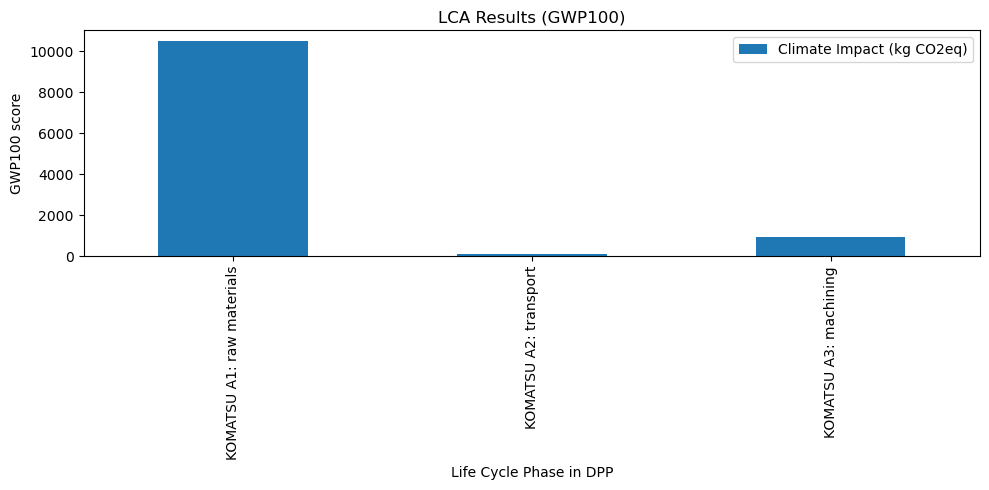

In [39]:
df_plot = df_komatsu_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("KOMATSU total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

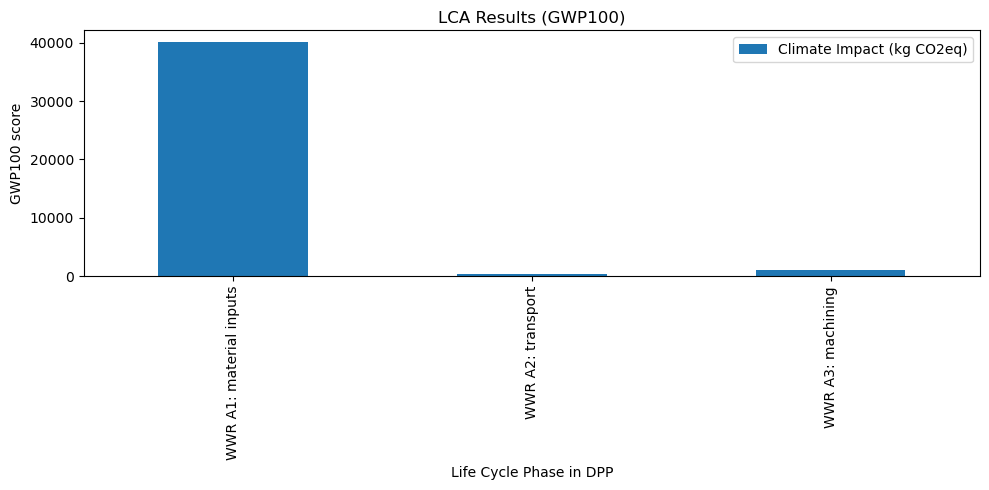

In [46]:
df_plot = df_wwr_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("WWR total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

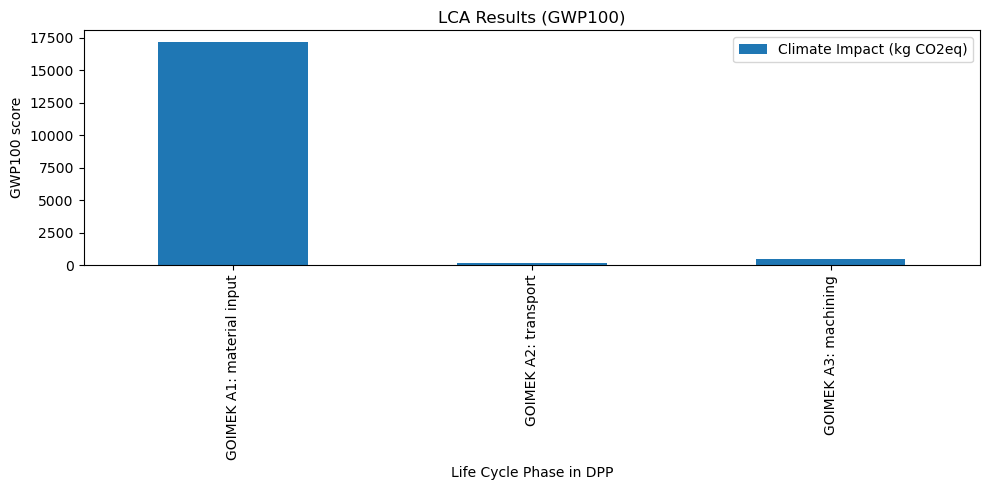

In [ ]:
df_plot = df_goimek_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("GOIMEK total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

#### 10) Plot contribution analysis

Running contribution analysis: KOMATSU total


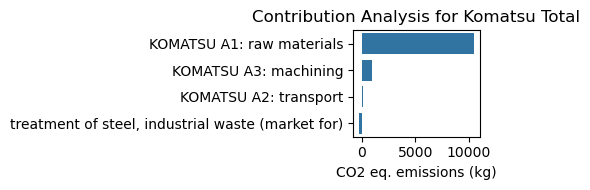

Running contribution analysis: KOMATSU A1: raw materials


C:\Users\TimWeber\AppData\Local\Temp\ipykernel_3916\835157069.py:24: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


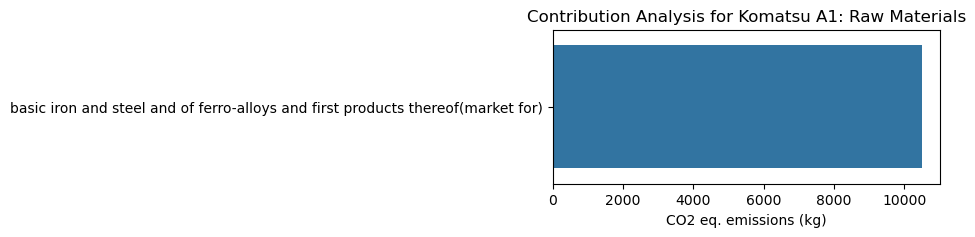

Running contribution analysis: KOMATSU A2: transport


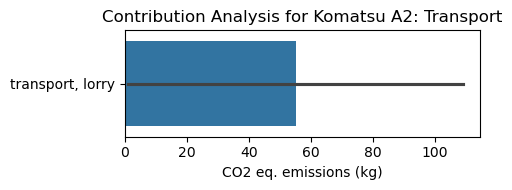

Running contribution analysis: KOMATSU A3: machining


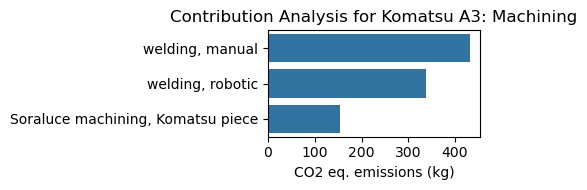

In [54]:
komatsu_ca = {}

for key, demand in komatsu_processes.items():
    print(f"Running contribution analysis: {key}")
    
    df = run_contribution_analysis(
        demand_object=demand,
        lcia_method=config.lcia_gwp100,
        max_level=1,
        cutoff=0.001
    )
    komatsu_ca[key] = df
    
    plot_contribution(
        df,
        title=f"Contribution Analysis for {key.replace('_', ' ').title()}"
    )

Running contribution analysis: WWR total


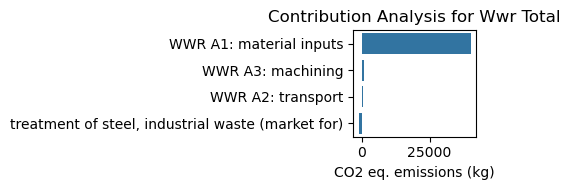

Running contribution analysis: WWR A1: material inputs


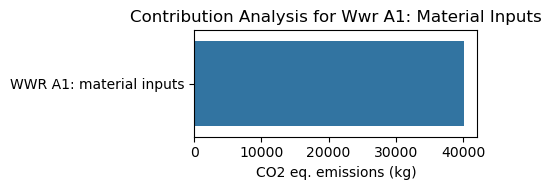

Running contribution analysis: WWR A2: transport


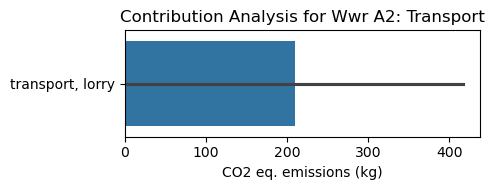

Running contribution analysis: WWR A3: machining


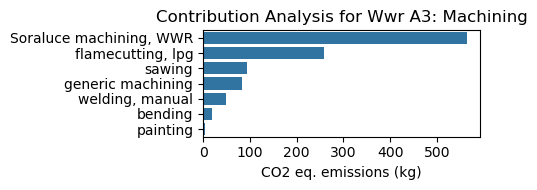

In [55]:
wwr_ca = {}

for key, demand in wwr_processes.items():
    print(f"Running contribution analysis: {key}")
    
    df = run_contribution_analysis(
        demand_object=demand,
        lcia_method=config.lcia_gwp100,
        max_level=1,
        cutoff=0.001
    )
    wwr_ca[key] = df
    
    plot_contribution(
        df,
        title=f"Contribution Analysis for {key.replace('_', ' ').title()}"
    )

Running contribution analysis: GOIMEK total


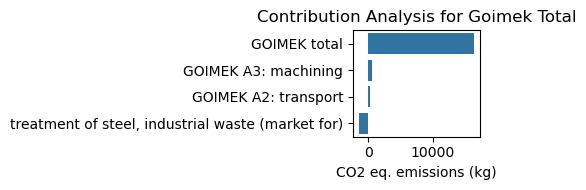

Running contribution analysis: GOIMEK A1: material input


C:\Users\TimWeber\AppData\Local\Temp\ipykernel_3916\835157069.py:24: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


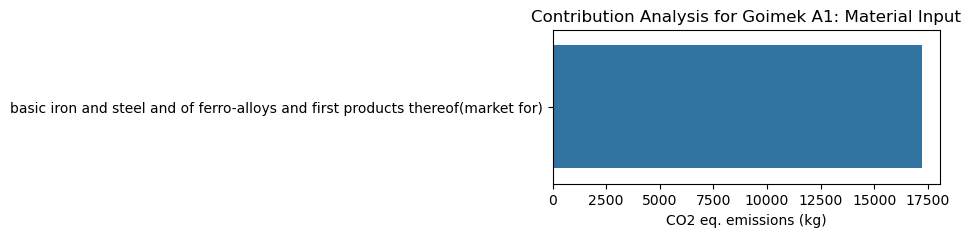

Running contribution analysis: GOIMEK A2: transport


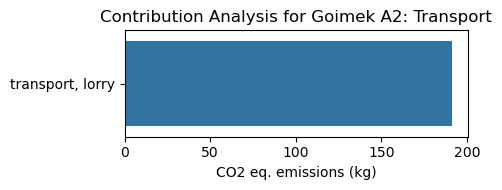

Running contribution analysis: GOIMEK A3: machining


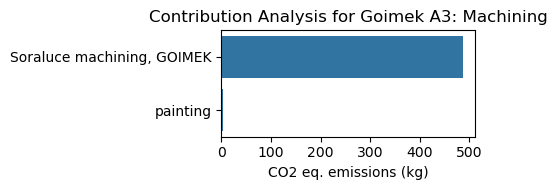

In [56]:
goimek_ca = {}

for key, demand in goimek_processes.items():
    print(f"Running contribution analysis: {key}")
    
    df = run_contribution_analysis(
        demand_object=demand,
        lcia_method=config.lcia_gwp100,
        max_level=1,
        cutoff=0.001
    )
    goimek_ca[key] = df
    
    plot_contribution(
        df,
        title=f"Contribution Analysis for {key.replace('_', ' ').title()}"
    )